# Klasyfikacja wieloetykietowa

![multilabel_intro.png](https://live.staticflickr.com/65535/54927204610_28ff033051.jpg)

*Obraz wygenerowany przez narzędzie generowania obrazów ChatGPT.*

## Wstęp

Współczesne zdjęcia często zawierają wiele obiektów i złożone sceny. Przykładem jest fotografia powyżej: widzimy na niej mężczyznę w marynarce, koszuli i krawacie, kobietę w sukni z welonem, grupę osób w letnich ubraniach, a całość rozgrywa się na plaży, na tle wody i zachodu słońca.

Gdybyśmy trzymali się klasycznego podejścia „jedno zdjęcie — jedna etykieta”, musielibyśmy wybrać tylko jedną kategorię: czy to zdjęcie przedstawia ślub, mężczyznę, kobietę, marynarkę, suknię, plażę…? W praktyce oznacza to sztuczne ograniczenie informacji.

Nie musimy jednak ograniczać się do jednej etykiety. Właśnie dlatego stosuje się klasyfikację wieloetykietową, która pozwala przypisać jednemu obrazowi wiele kategorii opisujących różne obiekty.
Zamiast wybierać jedną etykietę, możemy więc powiedzieć:
„Na tym zdjęciu występują instancje klas: człowiek, marynarka, koszula, krawat, suknia, plaża itd.”

## Zadanie

Twoim zadaniem jest zdefiniowanie i wytrenowanie sieci neuronowej do realizacji klasyfikacji wieloetykietowej. W zadaniu kompozycja zdjęcia będzie uproszczona w stosunku do przykładu powyżej. Na zdjęciach będą widoczne tylko ubrania, a Twoim zadaniem jest stworzenie modelu, który potrafi określić, czy dany rodzaj ubrania występuje na zdjęciu.

## Dane

W zadaniu masz do dyspozycji
* zbiór treningowy ($6318$ próbek),
* zbiór walidacyjny ($702$ próbek).

Zbiór testowy, na którym finalnie będzie oceniane Twoje rozwiązanie ma 780 próbek i jest niejawny. Został on stworzony w ten sam sposób co zbiór walidacyjny więc ma analogiczną charakterystykę.

Każda próbka to obraz o wymiarach $168 \times 168$ pikseli. Z każdym obrazkiem skojarzony jest 10-elementowy wektor z wartościami $0$ i $1$, który określa obecność danej klasy na obrazku. Informacja o tym jakiej części garderoby odpowiada poszczególny indeks w wektorze etykiet jest podana w słowniku `LABEL_NAMES` zdefiniowanym w jednej z komórek z kodem.

## Kryterium Oceny
Ostateczna ocena zadania będzie na podstawie średniej wartości miary $F1$ policzonej w ramach schematu *macro*.

Za to zadanie możesz zdobyć pomiędzy 0 a 100 punktów. Twój finalny wynik punktowy za rozwiązanie zadania obliczony będzie według poniższej funkcji (im wyższa wartość tym lepiej) przy dodatkowym zastosowaniu zaokrąglenia do wartości całkowitych:
$$
\mathrm{score} =
\begin{cases}
    0 & \text{jeżeli } {F1}\leq 0.57 \\
    100 \times \frac{{F1}- 0.57}{0.87 - 0.57} & \text{jeżeli } 0.57 < {F1} < 0.87 \\
    100 & \text{jeżeli } {F1} \geq 0.87
\end{cases}
$$

## Ograniczenia

- Twoje rozwiązanie będzie testowane na Platformie Konkursowej w środowisku z GPU. Na Platformie nie ma dostępu do Internetu, jednak możliwe jest skorzystanie z pretrenowanych modeli ResNet (*ResNet18*, *ResNet34*, *ResNet50*) z pakietu torchvision, które są zapisane w pamięci w formie plików. Aby z nich skorzystać, należy zastosować taką samą komendę w kodzie jak w przypadkach gdy Internet jest dostępny.
- Ewaluacja Twojego finalnego rozwiązania na danych testowych na Platformie Konkursowej nie może trwać dłużej niż 2.5 minuty z GPU.

## Pliki zgłoszeniowe

Ten notebook uzupełniony o Twoje rozwiązanie (definicję modelu, funkcję do treningu modelu i funkcję zwracającą predykcje modelu).

## Ewaluacja

Pamiętaj, że podczas sprawdzania flaga `FINAL_EVALUATION_MODE` zostanie ustawiona na `True`.

Za to zadanie możesz zdobyć pomiędzy 0 a 100 punktów. Liczba punktów, którą zdobędziesz, będzie wyliczona na (tajnym) zbiorze testowym na Platformie Konkursowej na podstawie wyżej wspomnianego wzoru, zaokrąglona do liczby całkowitej. Jeśli Twoje rozwiązanie nie będzie spełniało powyższych kryteriów lub nie będzie wykonywać się prawidłowo, otrzymasz za zadanie 0 punktów.

## Kod Startowy
W tej sekcji inicjalizujemy środowisko poprzez zaimportowanie potrzebnych bibliotek i funkcji. Przygotowany kod ułatwi Tobie efektywne operowanie na danych i budowanie właściwego rozwiązania.

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI PODCZAS WYSYŁANIA ##########################

FINAL_EVALUATION_MODE: bool = False  # Podczas sprawdzania ustawimy tę flagę na True.

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI PODCZAS WYSYŁANIA ##########################

import os

import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as fun
import torchvision

from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms

from tqdm import tqdm

from sklearn.metrics import f1_score

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI PODCZAS WYSYŁANIA ##########################

def seed_everything(seed: int):
    """Ustawia ziarno (seed) dla reprodukowalności wyników w Pythonie, NumPy oraz PyTorch."""

    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI PODCZAS WYSYŁANIA ##########################

# liczba klas do klasyfikacji
N_CLASSES: int = 10

# mapowanie indeksu klasy na jej nazwę
LABEL_NAMES: dict[int, str] = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI PODCZAS WYSYŁANIA ##########################

if not FINAL_EVALUATION_MODE:
    FILES: list[str] = [
        "runway-mnist/train-x.npz",
        "runway-mnist/train-y.npz",
        "runway-mnist/val-x.npz",
        "runway-mnist/val-y.npz"
    ]

    # pobierz dane na nowo, jeśli czegoś brakuje
    if not all(os.path.exists(file) for file in FILES):
        import gzip
        import tarfile
        import shutil

        if not os.path.exists("runway-mnist"):
            os.mkdir("runway-mnist")

        COMPRESSED_ARCHIVE = "runway-mnist.tar.gz"
        TAR_ARCHIVE  = COMPRESSED_ARCHIVE.rstrip(".gz")
        DOWNLOAD_URL = "https://drive.google.com/uc?id=1oNAFYdJyCVe3Po90KLUPxAG9HGuL7NSw"

        try:
            import gdown
        except ImportError as err:
            raise RuntimeError("Do pobrania zbioru danych potrzebujesz lokalnej instalacji pakietu gdown: `pip install gdown`") from err

        gdown.download(DOWNLOAD_URL, str(COMPRESSED_ARCHIVE), quiet=False)

        with gzip.open(COMPRESSED_ARCHIVE, "rb") as compressed:
            with open(TAR_ARCHIVE, "wb") as archive:
                shutil.copyfileobj(compressed, archive)

        os.remove(COMPRESSED_ARCHIVE)
        print(f"Zdekompresowano: {TAR_ARCHIVE}")

        with tarfile.open(TAR_ARCHIVE, "r") as tar:
            tar.extractall("runway-mnist")

        os.remove(TAR_ARCHIVE)
        print(f"Rozpakowano: {TAR_ARCHIVE}")

### Ładowanie danych

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI PODCZAS WYSYŁANIA ##########################

SEED: int = 42
seed_everything(SEED)

def load_x(usage) -> torch.Tensor:
    path = f"runway-mnist/{usage}-x.npz"
    return torch.tensor(np.load(path)["images"], dtype=torch.float32).unsqueeze(1)

def load_y(usage) -> torch.Tensor:
    path = f"runway-mnist/{usage}-y.npz"
    return torch.tensor(np.load(path)["labels"], dtype=torch.long)

train_dataset = TensorDataset(load_x("train"), load_y("train"))
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

val_dataset = TensorDataset(load_x("val"), load_y("val"))
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI PODCZAS WYSYŁANIA ##########################

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


## Funkcja oceniająca

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI PODCZAS WYSYŁANIA ##########################

def compute_score(f1: float) -> int:
    """Oblicza wynik punktowy na podstawie wartości metryki F1."""
    lower_bound = 0.57
    upper_bound = 0.87

    if f1 <= lower_bound:
        return 0
    elif lower_bound < f1 < upper_bound:
        return int(round(100 * (f1 - lower_bound) / (upper_bound - lower_bound)))
    else:
        return 100

def evaluate_algorithm(model, predict, loader) -> float:
    """Oblicza metryki oraz ocenia Twoje rozwiązanie na ich podstawie. Zwraca obliczoną wartość metryki F1."""
    preds = []
    labels = []
    model.eval()
    with torch.no_grad():
        for x, y in loader:
            prediction = predict(model, x.to(device)).cpu()
            preds.append(prediction)
            labels.append(y)

    predictions = torch.cat(preds)
    labels = torch.cat(labels)

    f1 = f1_score(labels.numpy(), predictions.numpy(), average="macro")
    points = compute_score(f1)
    print(f"Twój wynik F1: {f1:.3f}, co daje {points} punktów.")
    return f1

## Przykładowe rozwiązanie

Poniżej przedstawiamy uproszczone rozwiązanie, które demonstruje podstawową funkcjonalność
notebooka. Może ono posłużyć jako punkt wyjścia do opracowania Twojego rozwiązania.

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI PODCZAS WYSYŁANIA ##########################

class NaiveSolution(nn.Module):
    """Rozwiązanie naiwne."""

    def __init__(self):
        super().__init__()

    def forward(self, input: torch.Tensor) -> torch.Tensor:
        """Ten naiwny model przewiduje, że wszystkie klasy są na obrazku."""
        BATCH_SIZE = input.size(0)
        return torch.Tensor([1] * BATCH_SIZE * N_CLASSES).reshape(BATCH_SIZE, -1)

def train_naive(_: NaiveSolution):
    """Model, nie wymaga treningu."""
    pass

def predict_naive(model: NaiveSolution, input: torch.Tensor) -> torch.Tensor:
    """Nasz model zwraca od razu predykcje modelu, nie przetwarzamy ich dodatkowo."""
    return model(input).to(torch.long)

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI PODCZAS WYSYŁANIA ##########################
if not FINAL_EVALUATION_MODE:
    naive_solution = NaiveSolution().to(device)
    naive_solution.train()
    train_naive(naive_solution)
    evaluate_algorithm(naive_solution, predict_naive, val_loader)

Twój wynik F1: 0.545, co daje 0 punktów.


## Modelowe rozwiązanie

W tej sekcji opracujemy zaawansowane rozwiązanie dla problemu klasyfikacji wieloetykietowej. Wykorzystamy potencjał wstępnie wytrenowanych sieci neuronowych, w szczególności architekturę ResNet, aby osiągnąć wysoką wydajność. Przejdziemy przez kluczowe etapy, takie jak przygotowanie danych, konstrukcja modelu oparta na transfer learningu, a także strategie trenowania i ewaluacji, uwzględniając optymalizację hiperparametrów.

  - [1. Eksploracja danych](#data_exploration)
    - [1.1 Podstawowe informacje](#basic_information)
    - [1.2 Analiza danych](#data_analysis)
  - [2. Rozwiązanie z siecią CNN](#cnn_solution)
  - [3. Rozwiązanie z siecią ResNet](#resnet_solution)
    - [3.1 Przygotowanie danych do treningu](#resnet_data_preparation)
    - [3.2 Architektura modelu](#model_architecture)
    - [3.3 Losowe przeszukiwanie hiperparametrów i elastyczny próg predykcji](#random_search)
    - [3.4 Funkcja straty i optymalizator](#loss_function)
  - [4. Finalny model](#final_model)

<a id="data_exploration"></a>
### 1. Eksploracja danych

Zanim napiszemy klasyfikator, rozpoczniemy nasze rozwiązanie od analizy danych, aby lepiej zrozumieć problem.

<a id="basic_information"></a>
#### 1.1 Podstawowe informacje

Nasze dane składają się z dwóch zbiorów danych:
 - Treningowego (`train_dataset`)
 - Walidacyjnego (`val_dataset`)

 W obu zbiorach danych, mamy dostęp do przygotowanych obiektów klasy `torch.utils.data.DataLoader`, których możemy użyć do ładowania danych. Obiekty te nazywają się `train_loader` dla zbioru treningowego oraz `val_loader` dla zbioru walidacyjnego.

 Zacznijmy od sprawdzenia rozmiaru (liczby próbek) zbioru treningowego oraz walidacyjnego, a także rozmiaru próbek.



In [ ]:
print(f'Liczba próbek w zbiorze treningowym: {len(train_dataset)}')
print(f'Liczba próbek w zbiorze walidacyjnym: {len(val_dataset)}')

Liczba próbek w zbiorze treningowym: 6318
Liczba próbek w zbiorze walidacyjnym: 702


In [ ]:
example_train_images, example_train_labels = next(iter(train_loader))
print(f'Rozmiar obrazów w zbiorze treningowym {example_train_images[0].shape}')
print(f'Rozmiar wektora etykiet w zbiorze treningowym: {example_train_labels[0].shape}')
example_val_images, example_val_labels = next(iter(val_loader))
print(f'Rozmiar obrazów w zbiorze walidacyjnym {example_val_images[0].shape}')
print(f'Rozmiar wektora etykiet w zbiorze walidacyjnym: {example_val_labels[0].shape}')

Rozmiar obrazów w zbiorze treningowym torch.Size([1, 168, 168])
Rozmiar wektora etykiet w zbiorze treningowym: torch.Size([10])
Rozmiar obrazów w zbiorze walidacyjnym torch.Size([1, 168, 168])
Rozmiar wektora etykiet w zbiorze walidacyjnym: torch.Size([10])


Jak widzimy powyżej, mamy dostęp do 6318 próbek treningowych oraz 702 próbek walidacyjnych, co zgadza się z opisem zadania. Zdjęcia są rzeczywiście w rozmiarze $168 \times 168$ a nasz wektor etykiet ma 10 wymiarów, po jednym dla każdej klasy.

Dodatkowo, widzimy, że zdjęcia mają tylko jeden kanał koloru, co sugeruje, że zdjęcia są w odcieniach szarości (z ang. *grayscale*).

<a id="data_analysis"></a>
#### 1.2 Analiza danych

Znając podstawowe informacje o dostępnych danych, możemy je przeanalizować.

Zaczniemy od sprawdzenia wartości pikseli w obrazie, ich średniej, odchylenia standardowego, minimalnej i maksymalnej wartości. To pozwoli nam na sprawdzenie, czy zdjęcia są znormalizowane, czy nie.

In [ ]:
all_images = []
for images, _ in train_loader:
    all_images.append(images)

concatenated_images = torch.cat(all_images, dim=0)

mean_pixel_value = concatenated_images.mean()
std_pixel_value = concatenated_images.std()
min_pixel_value = concatenated_images.min()
max_pixel_value = concatenated_images.max()

print(f"Średnia wartość pikseli w zbiorze treningowym: {mean_pixel_value:.4f}")
print(f"Odchylenie standardowe pikseli w zbiorze treningowym: {std_pixel_value:.4f}")
print(f"Minimalna wartość pikseli w zbiorze treningowym: {min_pixel_value:.4f}")
print(f"Maksymalna wartość pikseli w zbiorze treningowym: {max_pixel_value:.4f}")

Średnia wartość pikseli w zbiorze treningowym: 17.0916
Odchylenie standardowe pikseli w zbiorze treningowym: 51.9870
Minimalna wartość pikseli w zbiorze treningowym: 0.0000
Maksymalna wartość pikseli w zbiorze treningowym: 255.0000


Jak widzimy, wartości pikseli są pomiędzy 0 a 255. To oznacza, że będziemy je musieli znormalizować podczas trenowania.

W następnej kolejności, wyświetlimy kilka przykładowych obrazów, razem z ich etykietami, aby zrozumieć jak one wyglądają.

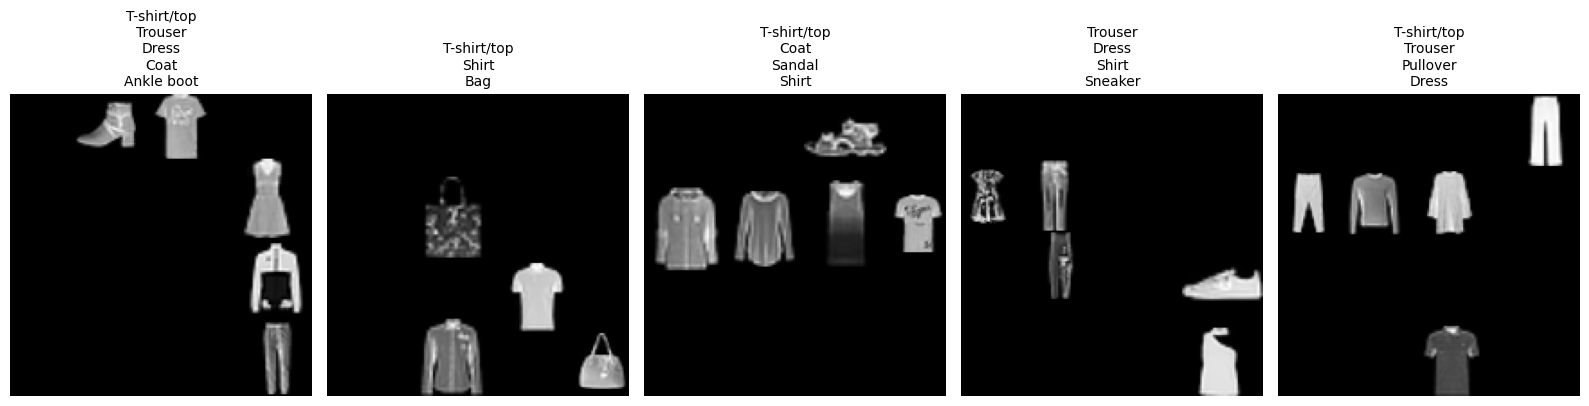

In [ ]:
import matplotlib.pyplot as plt

num_to_visualize = 5  #@param {type: 'number'}

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(1, num_to_visualize, figsize=(16, 4))
for i in range(num_to_visualize):
    # Usuwanie kanału koloru: (1, 168, 168) -> (168, 168)
    img = images[i].squeeze()

    # Sprawdzanie które etykiety są przyporządkowane do tego obrazu
    active_indices = (labels[i] == 1).nonzero(as_tuple=True)[0]
    active_labels = [LABEL_NAMES[idx.item()] for idx in active_indices]

    # Wyświetlenie obrazu
    axes[i].imshow(img, cmap="gray")
    axes[i].set_title("\n".join(active_labels), fontsize=10)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

Jak widzimy, zdjęcia są rzeczywiście w skali szarości, co potwierdza nasze wcześniejsze przypuszczenie.

Następnie, sprawdzimy również rozkład etykiet, aby zobaczyć, czy jakieś typy etykiet dominują rozkład, czy też rozkład jest równomierny.

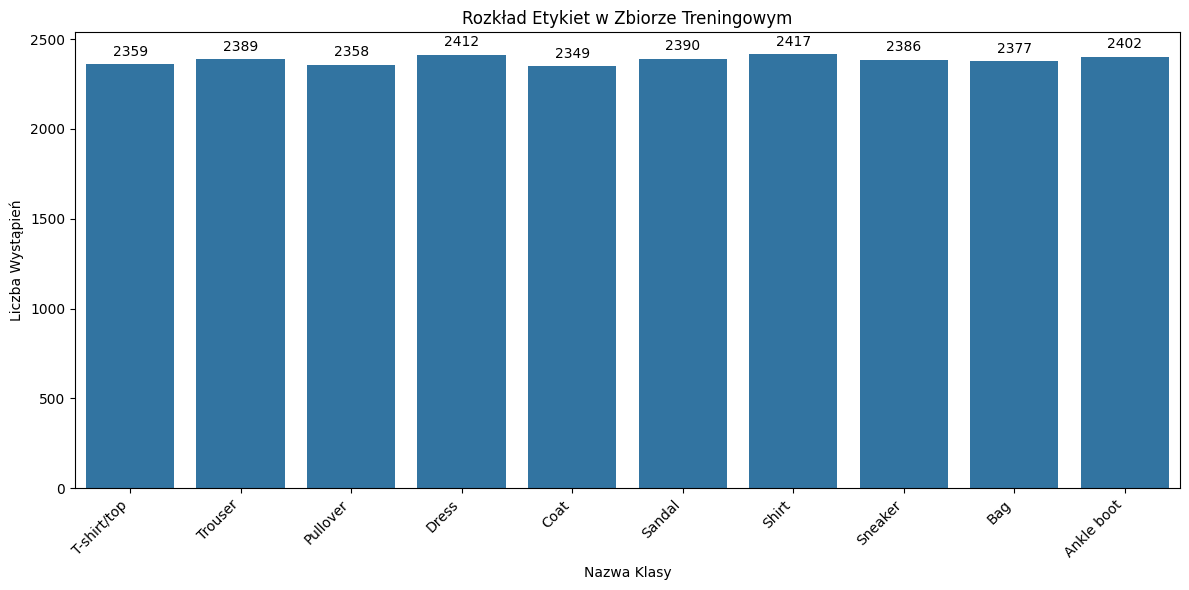

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

reduced = torch.concat([batch[1] for batch in train_loader], dim=0).sum(dim=0)
class_counts = reduced.tolist()
class_names = [LABEL_NAMES[i] for i in range(N_CLASSES)]

# DataFrame dla wyświetlania
df_counts = pd.DataFrame({
    'Class': class_names,
    'Count': class_counts
})

# Tworzenie wykresu słupkowego
plt.figure(figsize=(12, 6))
ax = sns.barplot(x='Class', y='Count', data=df_counts)
plt.title('Rozkład Etykiet w Zbiorze Treningowym')
plt.xlabel('Nazwa Klasy')
plt.ylabel('Liczba Wystąpień')
plt.xticks(rotation=45, ha='right')

# Liczby wystąpień nad każdym słupkiem
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points')

plt.tight_layout()
plt.show()

Jak widzimy, klasy rozłożone są równomiernie, co oznacza, że nie ma potrzeby stosowania dodatkowych technik pomagających w niezbilansowanych zbiorach danych.

Następnie, sprawdźmy, jak często poszczególne klasy występują razem na tych samych obrazach, analizując *warunkowe prawdopodobieństwo* ich występowania wzajemnego. Pomoże nam to zrozumieć zależności między różnymi typami odzieży. Każda komórka macierzy będzie reprezentować prawdopodobieństwo, że klasa z kolumny występuje, *pod warunkiem* że obecna jest klasa z wiersza.

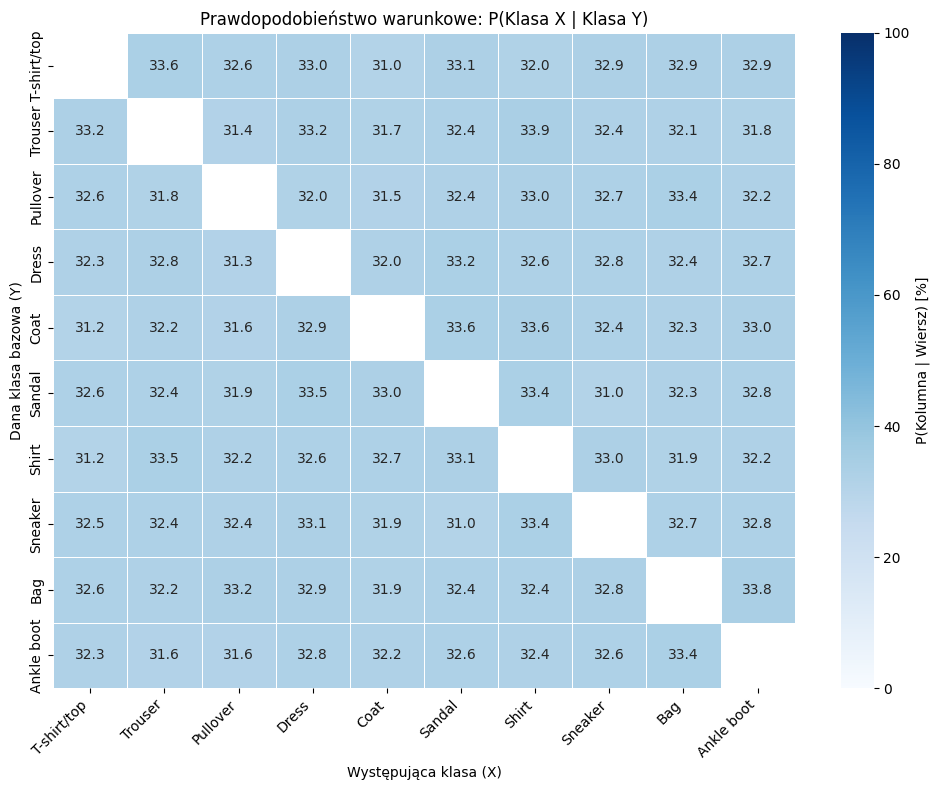

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

# Macierz współwystąpień
all_labels = torch.cat([batch[1] for batch in train_loader], dim=0).float()
co_occurrence = (all_labels.T @ all_labels).cpu().numpy()

# Prawdopodobieństwo warunkowe P(B|A) w %
class_totals = co_occurrence.diagonal()[:, np.newaxis]
cond_prob_matrix = (co_occurrence / class_totals) * 100.0

class_names = [LABEL_NAMES[i] for i in range(N_CLASSES)]
df_cond_prob = pd.DataFrame(
    cond_prob_matrix, index=class_names, columns=class_names
)

# Maska na przekątną
mask = np.eye(N_CLASSES, dtype=bool)

# Wykres
plt.figure(figsize=(10, 8))
sns.heatmap(
    df_cond_prob,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    mask=mask,
    cbar_kws={"label": "P(Kolumna | Wiersz) [%]"},
    linewidths=0.5,
    vmin=0,
    vmax=100,
)
plt.title("Prawdopodobieństwo warunkowe: P(Klasa X | Klasa Y)")
plt.xlabel("Występująca klasa (X)")
plt.ylabel("Dana klasa bazowa (Y)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Jak widzimy powyżej, prawdopodobieństwo warunkowe wystąpienia jednej klasy, gdy inna klasa jest obecna, wynosi około 32% dla każdej pary ubrań. Oznacza to brak znaczącej korelacji między dowolnymi parami obiektów.

Gdyby istniała widoczna korelacja, na przykład klasa A zawsze występowała z klasą B (P(B|A) = 100%), model mógłby się nauczyć, że klasa A zawsze idzie w parze z klasą B. Ponieważ brak jest tutaj jakiejkolwiek takiej silnej korelacji, nie musimy zastosowywać dodatkowych technik, aby radzić sobie z uprzedzeniami modelu wynikającymi z występowania razem.

<a id="cnn_solution"></a>
### 2. Rozwiązanie z siecią CNN

Aby lepiej zrozumieć zalety wykorzystania wstępnie wytrenowanych modeli, takich jak ResNet, spróbujmy najpierw zdefiniować i wytrenować prostą sieć konwolucyjną (CNN) od podstaw. Pokażemy, jak taka podstawowa architektura radzi sobie z naszym problemem klasyfikacji wieloetykietowej. Będzie to służyć jako punkt odniesienia dla porównania z rozwiązaniem opartym na ResNet.

**Uwaga:** Rozwiązanie sieci CNN używa już funkcji błędu `BCEWithLogitsLoss` oraz optymalizatora `AdamW`. Opiszemy te wybory dokładniej podczas dyskusji rozwiązania z siecią ResNet.

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=N_CLASSES):
        super(SimpleCNN, self).__init__()
        # Zmiana obrazu na mniejszy aby przyspieszyć trening i ułatwić modelowi
        # naukę
        self.resize = transforms.Resize((64, 64), antialias=True)

        # Warstwa konwolucyjna 1
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Warstwa konwolucyjna 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        # Warstwa konwolucyjna 3
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        # Obliczanie rozmiaru wejścia dla warstwy liniowej
        # Oryginalny obraz: 168x168
        # Zmieniony rozmiar na 64x64
        # Po conv1, bn1, pool: 32 kanały, (64/2)x(64/2) = 32x32
        # Po conv2, bn2, pool: 64 kanały, (32/2)x(32/2) = 16x16
        # Po conv3, bn3, pool: 128 kanałów, (16/2)x(16/2) = 8x8
        self.fc1 = nn.Linear(128 * 8 * 8, 512)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Skalowanie wartości pikseli z [0, 255] do [0, 1]
        x = x / 255.0

        x = self.resize(x)

        x = self.pool(fun.relu(self.bn1(self.conv1(x))))
        x = self.pool(fun.relu(self.bn2(self.conv2(x))))
        x = self.pool(fun.relu(self.bn3(self.conv3(x))))

        x = x.view(x.size(0), -1) # Spłaszczenie wyjścia dla warstw liniowych
        x = fun.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x


In [ ]:
def train_simple_cnn(model: SimpleCNN, epochs: int = 10, lr: float = 1e-3, weight_decay: float = 1e-4):
    """Trenuje model SimpleCNN z podanymi hiperparametrami."""

    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    print(f"\n--- Trening prostej sieci CNN, LR: {lr:.6f}, WD: {weight_decay:.6f} ---")

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
            images = images.to(device)
            # Etykiety muszą być float32 dla BCEWithLogitsLoss
            labels = labels.to(torch.float32).to(device)

            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
        print(f"Loss: {running_loss/len(train_loader):.4f}")

def predict_simple_cnn(model: SimpleCNN, input: torch.Tensor) -> torch.Tensor:
    """Przetwarza wyjście modelu SimpleCNN na binarne predykcje.
    (Ta funkcja jest analogiczna do `predict_solution`)"""
    model.eval()
    with torch.no_grad():
        outputs = model(input)
        # Zastosowanie sigmoid do wyjść przy progu 0.5, aby uzyskać predykcje binarne
        return (torch.sigmoid(outputs) > 0.5).to(torch.long)


In [ ]:
if not FINAL_EVALUATION_MODE:
    print("\n--- Ocena prostej sieci CNN ---")
    simple_cnn_model = SimpleCNN().to(device)
    train_simple_cnn(simple_cnn_model, epochs=50, lr=5e-4, weight_decay=1e-4)
    print("\nWyniki SimpleCNN na zbiorze walidacyjnym:")
    evaluate_algorithm(simple_cnn_model, predict_simple_cnn, val_loader)



--- Ocena prostej sieci CNN ---

--- Trening prostej sieci CNN, LR: 0.000500, WD: 0.000100 ---


Epoch 1/50: 100%|██████████| 99/99 [00:01<00:00, 50.45it/s]


Loss: 0.6757


Epoch 2/50: 100%|██████████| 99/99 [00:01<00:00, 62.71it/s]


Loss: 0.6327


...

Loss: 0.3230


Epoch 49/50: 100%|██████████| 99/99 [00:01<00:00, 63.85it/s]


Loss: 0.3249


Epoch 50/50: 100%|██████████| 99/99 [00:01<00:00, 63.01it/s]


Loss: 0.3234

Wyniki SimpleCNN na zbiorze walidacyjnym:
Twój wynik F1: 0.699, co daje 43 punktów.


Jak widać, prosta sieć CNN trenowana od podstaw osiąga wynik F1 na poziomie **0.699**, co daje **43 punkty**. Mimo że jest to znacznie lepszy wynik niż naiwne rozwiązanie (które osiągnęło 0.545 F1), nadal jest to niski wynik dla tego zadania. Jest to spowodowane kilkoma czynnikami:

1.  **Brak pre-treningu:** Model uczy się wszystkich cech od zera, co wymaga znacznie większej ilości danych i dłuższego czasu treningu, aby osiągnąć dobre wyniki.
2.  **Ograniczona ilość danych treningowych:** Aby skutecznie wytrenować złożoną sieć CNN od podstaw, potrzebna jest bardzo duża ilość danych. W naszym przypadku dostępny zbiór treningowy (6318 próbek) jest niewystarczający do nauki złożonych wzorców od zera.
3.  **Ograniczona architektura:** Prosta architektura CNN może nie być wystarczająco głęboka ani złożona, aby uchwycić wszystkie subtelne wzorce w obrazach.
4.  **Czas treningu:** Nawet z 50 epokami, model może nie osiągnąć pełnej konwergencji ani optymalnej wydajności.

Ten eksperyment z prostą siecią CNN pokazuje, jak trudne jest osiągnięcie wysokiej wydajności w zadaniach widzenia komputerowego bez wykorzystania zaawansowanych technik. Mimo prób optymalizacji sieci i jej parametrów, jest mało prawdopodobne, aby taka podstawowa architektura osiągnęła zadowalające rezultaty bez znacznego nakładu pracy, obejmującego wiele prób, strojenia i dostosowywania. To motywuje nas do użycia ResNet w dalszej części notebooka, co jest podejściem opartym na transfer learningu.

<a id="resnet_solution"></a>
### 3. Rozwiązanie z siecią ResNet

W tej sekcji skupimy się na implementacji rozwiązania opartego na architekturze ResNet. Wykorzystamy techniki transfer learningu, aby efektywnie rozwiązać problem klasyfikacji wieloetykietowej, bazując na modelu wytrenowanym na dużym zbiorze danych.

<a id="resnet_data_preparation"></a>
#### 3.1 Przygotowanie danych do treningu

Przed dalszymi krokami, wprowadzimy zmiany w sposobie przygotowania danych. Obrazy zostaną przekształcone tak, aby były zgodne z oczekiwaniami wstępnie trenowanego modelu ResNet, który był trenowany na zbiorze ImageNet. Obejmuje to:

1.  **Skalowanie wartości pikseli**: Zmiana zakresu wartości pikseli z `[0, 255]` na `[0, 1]`.
2.  **Powielenie kanałów**: Oryginalne obrazy są w skali szarości (jeden kanał). Zostaną one powielone do trzech kanałów, aby dopasować się do architektury modeli ImageNet, które oczekują wejść RGB.
3.  **Normalizacja**: Zastosowanie normalizacji za pomocą średniej i odchylenia standardowego zbioru danych ImageNet.

Te kroki preprocessingu zostaną zaimplementowane w metodzie `forward` klasy `Solution`. Poniżej przedstawiamy wizualizację przykładowych obrazów po skalowaniu, powieleniu kanałów (przed finalną normalizacją, aby zachować czytelność wizualną).

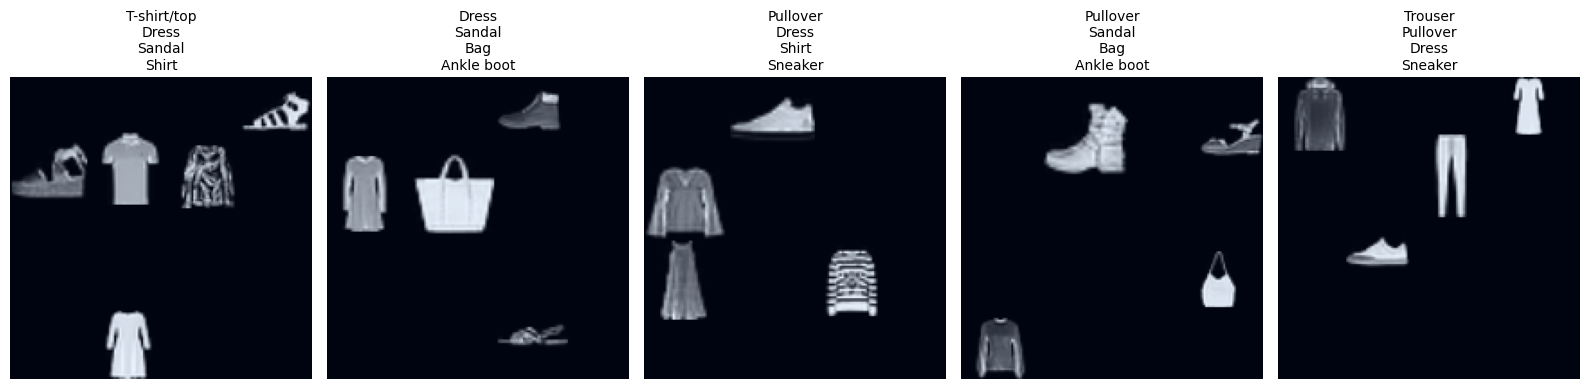

In [ ]:
import torchvision.transforms as transforms
import torch

# Parametry normalizacji ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Definicja normalizacji poza pętlą
normalize_transform = transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)

num_to_visualize = 5  #@param {type: 'number'}

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(1, num_to_visualize, figsize=(16, 4))
for i in range(num_to_visualize):
    img = images[i] # Kształt (1, 168, 168)

    img = img / 255.0 # Skalowanie do [0, 1]
    img = img.repeat(3, 1, 1) # Powielanie kanałów do 3 (C, H, W) i usunięcie batch_size dim

    # Normalizacja
    img_normalized = normalize_transform(img)

    # Aby wyświetlić znormalizowane obrazy, skalujemy wartości do zakresu [0, 1]
    # Uwaga: ta normalizacja jest tylko do wyświetlenia obrazu -
    # Nie będzie ona użyta podczas treningu
    img_display = img_normalized.cpu().clone()
    min_val = img_display.min()
    max_val = img_display.max()
    img_display = (img_display - min_val) / (max_val - min_val + 1e-5)

    # Zamiana do formatu (H, W, C) dla matplotlib
    img_display_numpy = img_display.permute(1, 2, 0).numpy()

    active_indices = (labels[i] == 1).nonzero(as_tuple=True)[0]
    active_labels = [LABEL_NAMES[idx.item()] for idx in active_indices]

    axes[i].imshow(img_display_numpy)
    axes[i].set_title("\n".join(active_labels), fontsize=10)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

Jak widzimy powyżej, wstępnie przetworzone obrazy wyglądają podobnie do poprzednich i nie różnią się znacząco.

Jednakże, normalizacja jest kluczowym krokiem przetwarzania wstępnego, zwłaszcza podczas korzystania z wstępnie wytrenowanego modelu, takiego jak ResNet. Jest to być może najważniejszy krok, ponieważ wagi wstępnie wytrenowanego modelu ResNet zostały nauczone na obrazach, których wartości pikseli zostały znormalizowane przy użyciu specyficznej średniej i odchylenia standardowego ImageNet (odpowiednio `[0.485, 0.456, 0.406]` dla średniej i `[0.229, 0.224, 0.225]` dla odchylenia standardowego w trzech kanałach kolorów).

Ta normalizacja skutecznie centruje i skaluje wartości pikseli do rozkładu, który rozumieją wstępnie wytrenowane wagi. Jeśli podamy modelowi nienormalizowane obrazy lub obrazy znormalizowane za pomocą innych statystyk, rozkład danych wejściowych będzie znacznie różnił się od tego, czego oczekuje model. To niedopasowanie oznacza, że nauczone filtry i wagi, które są bardzo wrażliwe na te zakresy wejściowe, mogą dać bezsensowne wyniki. Warstwy sieci mogą się nasycić, gradienty mogą zanikać lub eksplodować, a w istocie potężne, nauczone reprezentacje modelu stają się nieskuteczne.

Podsumowując, prawidłowa normalizacja danych jest kluczowa dla **dopasowania danych do domyślnych założeń wstępnie wytrenowanego modelu**. Zapewnia ona, że można skutecznie wykorzystać bogate cechy i wiedzę, którą model zdobył z milionów obrazów podczas początkowego trenowania, co prowadzi do znacznie lepszej wydajności i stabilniejszego trenowania dla konkretnego zadania.

<a id="model_architecture"></a>
#### 3.2 Architektura modelu

ResNet wprowadził koncepcję bloków rezydualnych, które dodają dane wejściowe do danych wyjściowych warstwy, umożliwiając sieci uczenie się funkcji resztowych zamiast bezpośrednich. Poniżej przedstawiono schematyczną architekturę bloku rezydualnego:

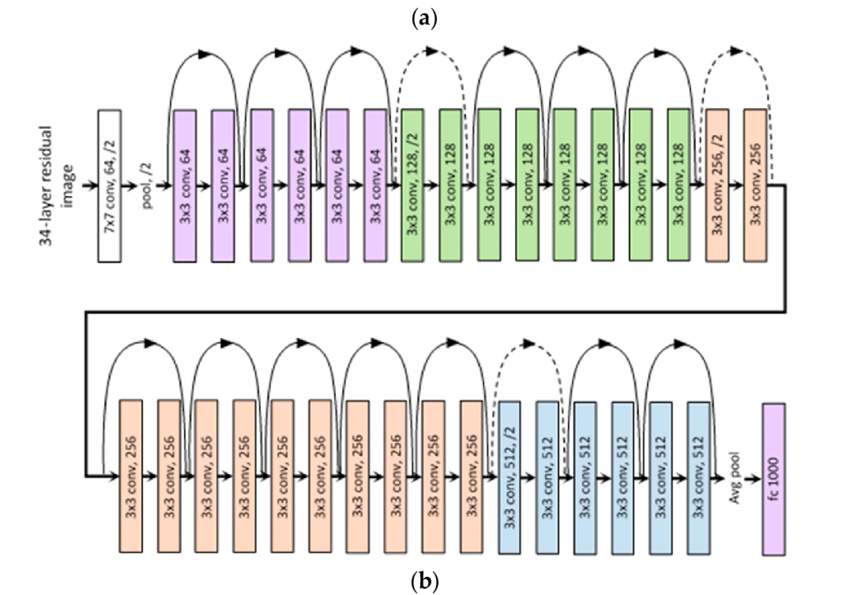

*Źródło: [Medium - Resnet Architecture Explained](https://medium.com/@siddheshb008/resnet-architecture-explained-47309ea9283d)*

Istnieje kilka kluczowych powodów, dla których używanie wytrenowanego modelu ResNet jest często preferowanym podejściem w zadaniach widzenia komputerowego:

1.  **Transfer Learning:** Modele ResNet, takie jak ResNet18, ResNet34 i ResNet50, zostały wytrenowane na ogromnych zbiorach danych, takich jak ImageNet, zawierającym miliony obrazów i tysiące kategorii. Podczas tego procesu nauczyły się one bogatych i ogólnych cech wizualnych (np. detekcji krawędzi, tekstur, wzorców), które są przydatne w szerokim zakresie zadań widzenia komputerowego. Wykorzystanie tych wstępnie nauczonych cech poprzez transfer learning pozwala naszemu modelowi rozpocząć od solidnej podstawy, zamiast uczyć się wszystkiego od zera.
2.  **Sprawdzona wydajność:** Architektury ResNet są znane ze swojej zdolności do osiągania najnowocześniejszych wyników w wielu benchmarkach. Ich innowacyjna koncepcja połączeń omijających (skip connections) pomaga w rozwiązywaniu problemu zanikania gradientu w bardzo głębokich sieciach, umożliwiając budowanie modeli o znacznie większej liczbie warstw, które są w stanie uchwycić bardziej złożone zależności w danych.
3.  **Mniej danych i czasu treningu:** Trening dużej sieci CNN od podstaw wymaga ogromnych ilości danych i znacznych zasobów obliczeniowych. Dzięki transfer learningowi możemy osiągnąć wysoką wydajność z mniejszą ilością danych specyficznych dla naszego zadania i w znacznie krótszym czasie treningu, ponieważ wagi modelu są już dobrze zainicjalizowane.
4.  **Unikanie projektowania cech:** Kiedy używamy wstępnie wytrenowanego modelu, unikamy skomplikowanego i czasochłonnego procesu ręcznego projektowania architektur CNN i strojenia ich od podstaw. Możemy skupić się na dostosowaniu ostatniej warstwy lub kilku warstw do naszego konkretnego zadania klasyfikacji wieloetykietowej.

Poniżej przedstawiamy naszą klasę `FlexibleSolution` zawierającą model ResNet. Klasa ta została dopasowana do naszego problemu poprzez dodanie dodatkowej warstwy liniowej, która użyta będzie do klasyfikacji, oraz wcześniej opisanych transformacji zdjęć wejściowych.


In [ ]:
class FlexibleSolution(nn.Module):
    """Klasa modelu, która może ładować różne architektury ResNet."""
    def __init__(self, model_name: str, learning_rate: float, weight_decay: float):
        super().__init__()
        self.model_name = model_name
        self.learning_rate = learning_rate
        self.weight_decay = weight_decay
        if model_name == 'resnet18':
            self.resnet = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT)
        elif model_name == 'resnet34':
            self.resnet = torchvision.models.resnet34(weights=torchvision.models.ResNet34_Weights.DEFAULT)
        elif model_name == 'resnet50':
            self.resnet = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.DEFAULT)
        else:
            raise ValueError(f"Nieobsługiwana nazwa modelu: {model_name}. Wybierz spośród 'resnet18', 'resnet34', 'resnet50'.")

        # Zastąpienie ostatniej warstwy klasyfikacyjnej dla naszego problemu wieloetykietowego
        num_features = self.resnet.fc.in_features
        self.resnet.fc = nn.Linear(num_features, N_CLASSES)

        # Definicja przekształcenia normalizacji
        self.normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                              std=[0.229, 0.224, 0.225])

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Skalowanie do [0, 1]
        x = x / 255.0

        # Powielanie kanałów
        x = x.repeat(1, 3, 1, 1)

        # Normalizacja
        x = self.normalize(x)

        return self.resnet(x)

<a id="random_search"></a>
#### 3.3 Losowe przeszukiwanie hiperparametrów i elastyczny próg predykcji

Losowe przeszukiwanie (Random Search) to podejście do optymalizacji hiperparametrów. W przeciwieństwie do przeszukiwania siatki (Grid Search), które testuje każdą kombinację dyskretnych wartości dla każdego hiperparametru, losowe przeszukiwanie próbuje wartości z określonego rozkładu dla każdego hiperparametru. Może to być bardziej efektywne, zwłaszcza gdy tylko kilka hiperparametrów ma znaczenie, ponieważ pozwala na szerszą eksplorację przestrzeni hiperparametrów przy tej samej liczbie prób.

W ramach tego procesu będziemy definiować zakres dla `learning_rate` i `weight_decay` dla optymalizatora `AdamW`, oraz wybierać jeden z dwóch modeli ResNet (`ResNet18`, `ResNet34`). Ostatecznie, nie uwzględniamy modelu `ResNet50` ze względu na potencjalnie wydłużony czas treningu, który mógłby nie zmieścić się w wymaganych 2.5 minutach.

In [ ]:
import random
import math

# Definiowanie przestrzeni poszukiwań dla hiperparametrów
HP_SEARCH_SPACE = {
    'model_name': ['resnet18', 'resnet34'],
    'learning_rate': [1e-5, 1e-3],  # Zakres dla współczynnika uczenia
    'weight_decay': [1e-3, 1e-1],   # Zakres dla współczynnika wag (weight decay)
}
NUM_TRIALS = 10 # Liczba prób w przeszukiwaniu losowym

In [ ]:
def predict_flexible_solution(model: FlexibleSolution, input: torch.Tensor, threshold: float) -> torch.Tensor:
    """Przetwarza wyjście modelu FlexibleSolution na binarne predykcje, używając progu predykcji.
    Potrzebne dla funkcji evaluate_algorithm."""
    model.eval()
    with torch.no_grad():
        outputs = model(input)
        # Zastosowanie sigmoid do wyjść przy danym progu, aby uzyskać predykcje binarne
        return (torch.sigmoid(outputs) > threshold).to(torch.long)

<a id="loss_function"></a>
#### 3.4 Funkcja straty i optymalizator

W naszym problemie klasyfikacji wieloetykietowej, gdzie każdy obraz może mieć wiele przypisanych etykiet, wybieramy odpowiednie narzędzia do optymalizacji modelu:

1.  **BCEWithLogitsLoss (Binary Cross-Entropy with Logits Loss)**:
    *   **Dlaczego jest używana:** Jest to funkcja straty powszechnie stosowana w zadaniach klasyfikacji wieloetykietowej. Łączy ona w sobie funkcję `Sigmoid` (która przekształca logity na prawdopodobieństwa w zakresie `[0, 1]`) i `Binary Cross-Entropy Loss` (BCE Loss). Dzięki temu nie musimy ręcznie stosować `Sigmoid` do wyjścia sieci, co zwiększa stabilność numeryczną (zapobiega problemom z niestabilnością gradientów dla bardzo dużych lub małych wartości logitów). Dla każdej etykiety i dla każdej próbki strata jest obliczana niezależnie, co jest kluczowe w scenariuszach wieloetykietowych, gdzie obecność jednej klasy nie wpływa na prawdopodobieństwo wystąpienia innej.

2.  **AdamW (Adam with Weight Decay Fix) Optimizer**:
    *   **Dlaczego jest używany:** `AdamW` to wariant popularnego optymalizatora `Adam`. W tradycyjnym `Adam` (i wielu innych optymalizatorach) `weight decay` (regularyzacja L2) jest dodawany do funkcji straty. Jednak w `AdamW` `weight decay` jest stosowany bezpośrednio do wag w sposób, który jest matematycznie równoważny dodaniu L2 do funkcji straty w przypadku optymalizatora SGD, ale niekoniecznie w przypadku adaptacyjnych optymalizatorów, takich jak `Adam`.
    *   **Korzyści:** Ta modyfikacja sprawia, że `weight decay` w `AdamW` działa bardziej efektywnie jako mechanizm regularyzacji, co często prowadzi do lepszych wyników generalizacji modelu (mniej *overfittingu*). Jest to szczególnie ważne w głębokich sieciach neuronowych, gdzie *overfitting* jest częstym problemem, a dokładna regularyzacja wag może znacznie poprawić wydajność.

In [ ]:
def train_and_evaluate_model(model: FlexibleSolution, epochs: int = 5, evaluate: bool = True, evaluation_threshold: float = 0.5) -> float | None:
    """Trenuje i ocenia model FlexibleSolution z podanymi hiperparametrami,
    zwracając wynik F1."""

    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.AdamW(model.parameters(), lr=model.learning_rate, weight_decay=model.weight_decay)

    print(f"\n--- Trening z modelem: {model.model_name}, LR: {model.learning_rate:.6f}, WD: {model.weight_decay:.6f}")

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
            images = images.to(device)
            labels = labels.to(torch.float32).to(device)

            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
        print(f"Loss: {running_loss/len(train_loader):.4f}")

    # Ocena modelu po treningu, używając zdefiniowanej funkcji predict_flexible_solution
    if not evaluate:
        return None
    # Użyj lambda, aby przekazać evaluation_threshold do predict_flexible_solution wewnątrz evaluate_algorithm
    f1 = evaluate_algorithm(model, lambda m, i: predict_flexible_solution(m, i, evaluation_threshold), val_loader)
    return f1

In [ ]:
best_f1_score = -1
best_hyperparameters = {}

print(f"Rozpoczynanie losowego przeszukiwania dla {NUM_TRIALS} prób...")

for trial in range(NUM_TRIALS):
    # Losowy wybór hiperparametrów z zdefiniowanej przestrzeni poszukiwań
    sampled_model_name = random.choice(HP_SEARCH_SPACE['model_name'])

    # Próbkowanie learning_rate i weight_decay w skali logarytmicznej
    log_lr_min = math.log(HP_SEARCH_SPACE['learning_rate'][0])
    log_lr_max = math.log(HP_SEARCH_SPACE['learning_rate'][1])
    sampled_lr = math.exp(random.uniform(log_lr_min, log_lr_max))

    log_wd_min = math.log(HP_SEARCH_SPACE['weight_decay'][0])
    log_wd_max = math.log(HP_SEARCH_SPACE['weight_decay'][1])
    sampled_wd = math.exp(random.uniform(log_wd_min, log_wd_max))

    # Model FlexibleSolution nie przechowuje prediction_threshold
    model = FlexibleSolution(sampled_model_name, sampled_lr, sampled_wd).to(device)
    # Użyj domyślnego progu 0.5 do oceny podczas random search
    current_f1 = train_and_evaluate_model(model, evaluation_threshold=0.5)

    if current_f1 is not None and current_f1 > best_f1_score:
        best_f1_score = current_f1
        best_hyperparameters = {
            'model_name': sampled_model_name,
            'learning_rate': sampled_lr,
            'weight_decay': sampled_wd
        }
    print(f"Próba {trial+1}/{NUM_TRIALS} zakończona. Wynik F1: {current_f1:.4f}")

print("\n--- Wyniki Losowego Przeszukiwania ---")
print(f"Najlepszy wynik F1: {best_f1_score:.4f}")
print(f"Najlepsze hiperparametry: {best_hyperparameters}")

Rozpoczynanie losowego przeszukiwania dla 10 prób...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 129MB/s]



--- Trening z modelem: resnet18, LR: 0.000340, WD: 0.002314


Epoch 1/5: 100%|██████████| 99/99 [00:14<00:00,  7.06it/s]


Loss: 0.3534


...

Loss: 0.2209


Epoch 4/5: 100%|██████████| 99/99 [00:23<00:00,  4.24it/s]


Loss: 0.1572


Epoch 5/5: 100%|██████████| 99/99 [00:23<00:00,  4.23it/s]


Loss: 0.1034
Twój wynik F1: 0.858, co daje 96 punktów.
Próba 10/10 zakończona. Wynik F1: 0.8578

--- Wyniki Losowego Przeszukiwania ---
Najlepszy wynik F1: 0.8721
Najlepsze hiperparametry: {'model_name': 'resnet18', 'learning_rate': 0.0003404463132838153, 'weight_decay': 0.0023143819568036}


***Uwaga:** Powyższa komórka powinna zostać usunięta w ostatecznym rozwiązaniu aby zmieścić się w limicie czasowym. Najlepsze hiperparametry należy skopiować do klasy `Solution`, zdefiniowanej poniżej.*

<a id="final_model"></a>
### 4. Finalny model

Po zakończeniu przeszukiwania losowego, trenujemy finalny model `solution` używając najlepszych znalezionych hiperparametrów. W ten sposób możemy zapewnić, że finalny model jest trenowany z optymalnymi parametrami.

Na wytrenowanym modelu, możemy jednak dokonać jeszcze jednej optymalizacji.

Tradycyjnie, w klasyfikacji binarnej lub wieloetykietowej, często stosuje się stały próg `0.5` do konwersji prawdopodobieństw na binarne predykcje. Jednak próg `0.5` nie zawsze jest najlepszy, zwłaszcza gdy optymalizujemy pod kątem metryk takich jak F1, które balansują precyzję i kompletność (recall).

Dlatego, w ostatecznym modelu przeszukamy dodatkowo wartość progu decyzyjnego optymalizowanego pod kątem metryki F1. Przeszukanie to będzie prostym skanem liniowym po wartościach od 0.05 do 0.95.

In [ ]:
def calibrate_threshold(model: nn.Module, loader: DataLoader) -> float:
    """Wyliczanie optymalnego progu predykcji."""
    model.eval()
    all_probs = []
    all_labels = []

    # Predykcje wyliczamy tylko raz, aby przyspieszyć rozwiązanie
    with torch.no_grad():
        for x, y in loader:
            logits = model(x.to(device))
            probs = torch.sigmoid(logits).cpu()
            all_probs.append(probs)
            all_labels.append(y)

    all_probs = torch.cat(all_probs).numpy()
    all_labels = torch.cat(all_labels).numpy()

    best_f1 = -1.0
    best_thresh = 0.5

    # Przeszukiwanie liniowe
    for thresh in np.linspace(0.05, 0.95, 19):
        preds = (all_probs > thresh).astype(int)
        score = f1_score(all_labels, preds, average="macro")
        if score > best_f1:
            best_f1 = score
            best_thresh = thresh

    return float(best_thresh)

In [ ]:
class Solution(nn.Module):
    """
    Klasa przechowująca finalne rozwiązanie z użyciem klasy FlexibleSolution
    opartej na architekturze ResNet.
    """
    def __init__(self,
                 # Zastąp wartościami znalezionymi przez przeszukiwanie
                 best_model_name: str = 'resnet18',
                 best_learning_rate: float = 0.0003404463132838153,
                 best_weight_decay: float = 0.0023143819568036):
        super().__init__()
        self.model = FlexibleSolution(best_model_name,
                                      best_learning_rate,
                                      best_weight_decay)
        # Próg predykcji będzie kalibrowany po treningu
        self.calibrated_prediction_threshold: float = 0.5 # Wartość domyślna, zostanie zaktualizowana po treningu

    def forward(self, input: torch.Tensor) -> torch.Tensor:
        """Inferencja modelu"""
        return self.model(input)

def train_solution(solution: Solution):
    """Pętla treningowa dla Twojego modelu."""
    # Trening modelu
    train_and_evaluate_model(solution.model, epochs=5, evaluate=False)

    # Kalibracja progu predykcji po treningu
    solution.calibrated_prediction_threshold = calibrate_threshold(solution, val_loader)
    print(f"Najlepszy próg po kalibracji: {solution.calibrated_prediction_threshold:.4f}")


def predict_solution(model: Solution, input: torch.Tensor) -> torch.Tensor:
    """Przetwarza wyjście modelu Solution na binarne predykcje, używając skalibrowanego progu.
    Ta funkcja jest proxy dla predict_flexible_solution, aby dopasować się do API evaluate_algorithm."""
    return predict_flexible_solution(model.model, input, model.calibrated_prediction_threshold)

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI PODCZAS WYSYŁANIA #########################

solution = Solution().to(device)
solution.train()

train_solution(solution)


--- Trening z modelem: resnet18, LR: 0.000340, WD: 0.002314


Epoch 1/5: 100%|██████████| 99/99 [00:14<00:00,  6.98it/s]


Loss: 0.3529


Epoch 2/5: 100%|██████████| 99/99 [00:14<00:00,  6.62it/s]


Loss: 0.2008


...

Loss: 0.1374


Epoch 4/5: 100%|██████████| 99/99 [00:13<00:00,  7.09it/s]


Loss: 0.0921


Epoch 5/5: 100%|██████████| 99/99 [00:13<00:00,  7.15it/s]


Loss: 0.0557
Najlepszy próg po kalibracji: 0.3000


Jak widzimy powyżej, optymalny próg rzeczywiście nie wynosił 0.5.

## Ewaluacja

Poniższy kod będzie służył ewaluacji rozwiązania. Po wysłaniu rozwiązania do nas zostanie wykonana funkcja `evaluate_algorithm(solution, predict_solution)`, t.j. prawie identyczny kod jak niżej będzie się uruchamiał na zbiorze testowym dostępnym tylko dla sprawdzających zadania.

Upewnij się przed wysłaniem, że cały notebook wykonuje się od początku do końca bez błędów i bez ingerencji użytkownika po wykonaniu polecenia `Run All`.

In [ ]:
######################### NIE ZMIENIAJ TEJ KOMÓRKI PODCZAS WYSYŁANIA #########################

if not FINAL_EVALUATION_MODE:
    evaluate_algorithm(solution, predict_solution, val_loader)

Twój wynik F1: 0.886, co daje 100 punktów.
